In [43]:
!pip install --upgrade binance-historical-data plotly -q

In [44]:
import yfinance as yf



In [78]:
ticker = 'GC=F'
data_frequency = '30m'
data = yf.download(ticker, start='2025-01-01', end='2025-07-25', interval = '1h')
data.columns = data.columns.droplevel(1)
data

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Datetime,,,,,
2025-01-02 05:00:00+00:00,2646.000000,2648.800049,2645.100098,2645.800049,2454
2025-01-02 06:00:00+00:00,2646.500000,2647.800049,2643.600098,2646.000000,2488
2025-01-02 07:00:00+00:00,2647.899902,2648.000000,2644.699951,2646.399902,1936
2025-01-02 08:00:00+00:00,2648.800049,2650.199951,2642.600098,2648.000000,5375
2025-01-02 09:00:00+00:00,2649.000000,2652.899902,2648.899902,2649.000000,4311
...,...,...,...,...,...
2025-07-24 23:00:00+00:00,3371.800049,3373.699951,3368.300049,3370.300049,1855
2025-07-25 00:00:00+00:00,3375.199951,3376.600098,3370.699951,3371.699951,2700
2025-07-25 01:00:00+00:00,3372.500000,3375.800049,3368.800049,3375.300049,3863


In [79]:
# Calculate the candle length - difference between Close & Open
data['Close-Open'] = data['Close'] - data['Open']
data['Candle'] = np.where(data['Close-Open'] >= 0, 'green', 'red')
data['Mean_CO'] = abs(data['Close-Open']).rolling(window=5).mean()

# Calculate the boundary for signal
data['Signal'] = data['Mean_CO']*15

# Position to take
conditions = [
    (abs(data['Close-Open']) < data['Signal'].shift(1)),
    (abs(data['Close-Open']) >= data['Signal'].shift(1)) & (data['Candle'].shift(1)=='green'),
    (abs(data['Close-Open']) >= data['Signal'].shift(1)) & (data['Candle'].shift(1)=='red')
]
choices = [0, -1, 1]
data['Position'] = np.select(conditions, choices, default=0)

has_non_zero = (data['Position'] != 0).sum()
print("Column has non-zero:", has_non_zero)

data.head (500) # Display the DataFrame

Column has non-zero: 1


Price,Close,High,Low,Open,Volume,Close-Open,Candle,Mean_CO,Signal,Position
Datetime,,,,,,,,,,
2025-01-02 05:00:00+00:00,2646.000000,2648.800049,2645.100098,2645.800049,2454,0.199951,green,NaN,NaN,0
2025-01-02 06:00:00+00:00,2646.500000,2647.800049,2643.600098,2646.000000,2488,0.500000,green,NaN,NaN,0
2025-01-02 07:00:00+00:00,2647.899902,2648.000000,2644.699951,2646.399902,1936,1.500000,green,NaN,NaN,0
2025-01-02 08:00:00+00:00,2648.800049,2650.199951,2642.600098,2648.000000,5375,0.800049,green,NaN,NaN,0
2025-01-02 09:00:00+00:00,2649.000000,2652.899902,2648.899902,2649.000000,4311,0.000000,green,0.600000,9.000000,0
...,...,...,...,...,...,...,...,...,...,...
2025-02-03 17:00:00+00:00,2857.199951,2862.000000,2833.300049,2852.800049,7481,4.399902,green,5.860010,87.900146,0
2025-02-03 18:00:00+00:00,2857.300049,2861.199951,2855.000000,2856.699951,6394,0.600098,green,5.200000,78.000000,0
2025-02-03 19:00:00+00:00,2858.000000,2861.199951,2834.199951,2857.199951,2812,0.800049,green,4.620020,69.300293,0


In [80]:
data['PnL'] = 0
data['Unrealised'] = 0
for i in range(len(data)-1):
  if data['Position'][i] != data['Position'][i+1]:
    data['Unrealised'][i+1] = 0.0005
  data['PnL'][i+1] = (data['Close'][i+1]/data['Open'][i+1]-1)*data['Position'][i]

data['Real_returns'] = data['PnL']-data['Unrealised']

data.head(50)


Price,Close,High,Low,Open,Volume,Close-Open,Candle,Mean_CO,Signal,Position,PnL,Unrealised,Real_returns
Datetime,,,,,,,,,,,,,
2025-01-02 05:00:00+00:00,2646.000000,2648.800049,2645.100098,2645.800049,2454,0.199951,green,NaN,NaN,0,0.0,0.0,0.0
2025-01-02 06:00:00+00:00,2646.500000,2647.800049,2643.600098,2646.000000,2488,0.500000,green,NaN,NaN,0,0.0,0.0,0.0
2025-01-02 07:00:00+00:00,2647.899902,2648.000000,2644.699951,2646.399902,1936,1.500000,green,NaN,NaN,0,0.0,0.0,0.0
2025-01-02 08:00:00+00:00,2648.800049,2650.199951,2642.600098,2648.000000,5375,0.800049,green,NaN,NaN,0,0.0,0.0,0.0
2025-01-02 09:00:00+00:00,2649.000000,2652.899902,2648.899902,2649.000000,4311,0.000000,green,0.600000,9.000000,0,0.0,0.0,0.0
2025-01-02 10:00:00+00:00,2654.699951,2659.399902,2644.699951,2648.899902,10661,5.800049,green,1.720020,25.800293,0,0.0,0.0,0.0
2025-01-02 11:00:00+00:00,2654.600098,2656.699951,2652.800049,2654.800049,3203,-0.199951,red,1.660010,24.900146,0,0.0,0.0,0.0
2025-01-02 12:00:00+00:00,2656.399902,2659.899902,2653.199951,2654.699951,5260,1.699951,green,1.700000,25.500000,0,0.0,0.0,0.0
2025-01-02 13:00:00+00:00,2656.300049,2660.699951,2648.199951,2656.399902,16368,-0.099854,red,1.559961,23.399414,0,0.0,0.0,0.0


In [81]:
def get_periods_per_year(freq: str) -> int:
    if freq.endswith('m'):  # phút
        minutes = int(freq[:-1])
        return int(365 * 24 * 60 / minutes)
    elif freq.endswith('h'):  # giờ
        hours = int(freq[:-1])
        return int(365 * 24 / hours)
    elif freq.endswith('d'):  # ngày
        return 365
    elif freq.endswith('w'):  # tuần
        return 52
    else:
        raise ValueError(f"Không hỗ trợ định dạng data_frequency: {freq}")

def calculate_sharpe_ratio(returns_series: pd.Series, data_frequency: str, annualized_risk_free_rate: float = 0.03) -> float:
    """
    Tính toán Sharpe Ratio hàng năm từ một chuỗi lợi nhuận theo kỳ.

    Args:
        returns_series (pd.Series): Chuỗi lợi nhuận của chiến lược theo từng kỳ.
        data_frequency (str): Tần suất của dữ liệu ('15m', '1H', '1D').
        annualized_risk_free_rate (float): Lãi suất phi rủi ro hàng năm.

    Returns:
        float: Giá trị Sharpe Ratio đã được quy đổi ra năm.
    """
    # Xử lý trường hợp không có giao dịch hoặc không có biến động
    if returns_series.std() == 0 or pd.isna(returns_series.std()):
        return 0.0

    # 1. Lấy số kỳ trong một năm
    periods_per_year = get_periods_per_year(data_frequency)

    # 2. Quy đổi lãi suất phi rủi ro ra theo từng kỳ
    rf_per_period = annualized_risk_free_rate / periods_per_year

    # 3. Tính toán Sharpe Ratio
    # Lợi nhuận trung bình mỗi kỳ trừ đi lãi suất phi rủi ro mỗi kỳ
    excess_return_mean = returns_series.mean() - rf_per_period

    # Sharpe Ratio hàng ngày = Lợi nhuận vượt trội trung bình / Độ lệch chuẩn lợi nhuận
    sharpe_ratio = excess_return_mean / returns_series.std()

    # 4. Quy đổi ra Sharpe Ratio hàng năm
    annualized_sharpe = sharpe_ratio * np.sqrt(periods_per_year)

    return annualized_sharpe

def calculate_max_drawdown(returns_series: pd.Series) -> float:
    """Tính toán Maximum Drawdown từ một chuỗi lợi nhuận."""
    equity_curve = (1 + returns_series).cumprod()
    peak = equity_curve.expanding(min_periods=1).max()
    drawdown = (equity_curve - peak) / peak
    return drawdown.min()


period_per_year = get_periods_per_year(data_frequency)
real_return = data['Real_returns']

sharpe_ratio = calculate_sharpe_ratio(real_return, data_frequency)
max_drawdown = calculate_max_drawdown(real_return)


# Calculate cumulative returns
Cumulative_Return = (1 + data['Real_returns']).cumprod()


# # Calculate Drawdown
# data['Peak'] = data['Cumulative_Return'].cummax()
# data['Drawdown'] = data['Peak'] - data['Cumulative_Return']

# # Calculate Max Drawdown
# max_drawdown = data['Drawdown'].max()

# # Calculate Average Drawdown (excluding zero drawdown periods)
# average_drawdown = data[data['Drawdown'] > 0]['Drawdown'].mean()

print(f"Sharpe Ratio: {sharpe_ratio}")
print(f"Max Drawdown: {max_drawdown}")
print(f"Return: {Cumulative_Return}")

# pnls = data['PnL']
# for pnl in pnls:
#   if pnl != 0:
#     print (pnl)

Sharpe Ratio: -2.578560864748493
Max Drawdown: -0.0004999999999999449
Return: Datetime
2025-01-02 05:00:00+00:00    1.000000
2025-01-02 06:00:00+00:00    1.000000
2025-01-02 07:00:00+00:00    1.000000
2025-01-02 08:00:00+00:00    1.000000
2025-01-02 09:00:00+00:00    1.000000
                               ...   
2025-07-24 23:00:00+00:00    1.002353
2025-07-25 00:00:00+00:00    1.002353
2025-07-25 01:00:00+00:00    1.002353
2025-07-25 02:00:00+00:00    1.002353
2025-07-25 03:00:00+00:00    1.002353
Name: Real_returns, Length: 3257, dtype: float64


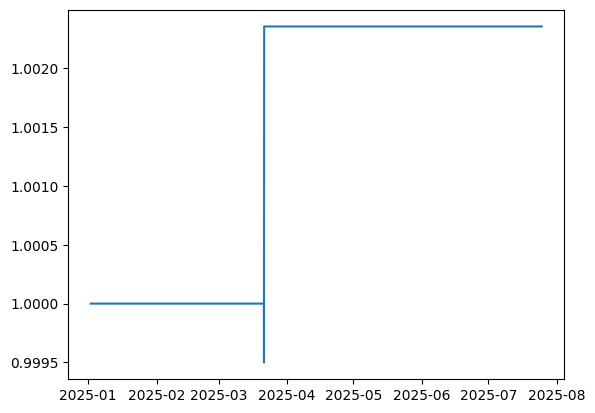

In [82]:
dates = data.index
# Plot profit
# plt.plot(unrealised_dates, np.cumprod(1+np.array(unrealised))-1)
# plt.plot(dates, np.cumprod(1+np.array(pnls))-1)
plt.plot(dates, Cumulative_Return)
# plt.plot(unrlzd_dates,np.cumprod(1+np.array(unrlzd)))
#plt.plot(unrlzd_dates, np.cumsum(unrlzd))